Step 1 Data ingestion

In [0]:
import pandas as pd
import numpy as np

In [0]:
products = spark.read.table("analystlab.default.products_2").toPandas()

display(products)

product_id,created_at,product_name
1,3/19/2012 8:00,The Original Mr. Fuzzy
2,1/6/2013 13:00,The Forever Love Bear
3,12/12/2013 9:00,The Birthday Sugar Panda
4,2/5/2014 10:00,The Hudson River Mini bear


 Examine shape, columns and data types**

In [0]:
products.shape

(4, 3)

In [0]:
products.describe()

,product_id,created_at,day,week,month,year,hour,quarter
count,4.000000,4,4.000000,4.0,4.000000,4.000000,4.000000,4.00
mean,2.500000,2013-04-26 22:00:00,10.500000,17.25,4.500000,2013.000000,10.000000,1.75
min,1.000000,2012-03-19 08:00:00,5.000000,1.0,1.000000,2012.000000,8.000000,1.00
25%,1.750000,2012-10-25 05:45:00,5.750000,4.75,1.750000,2012.750000,8.750000,1.00
50%,2.500000,2013-06-25 11:00:00,9.000000,9.0,2.500000,2013.000000,9.500000,1.00
75%,3.250000,2013-12-26 03:15:00,13.750000,21.5,5.250000,2013.250000,10.750000,1.75
max,4.000000,2014-02-05 10:00:00,19.000000,50.0,12.000000,2014.000000,13.000000,4.00
std,1.290994,NaN,6.454972,22.291628,5.066228,0.816497,2.160247,1.50


In [0]:
print(products.columns)

Index(['product_id', 'created_at', 'product_name'], dtype='object')


In [0]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_id    4 non-null      int64 
 1   created_at    4 non-null      object
 2   product_name  4 non-null      object
dtypes: int64(1), object(2)
memory usage: 228.0+ bytes


**Identify missing values and duplicate records**

In [0]:
 # Check missing values
print(products.isnull().sum())

product_id      0
created_at      0
product_name    0
dtype: int64


In [0]:
 # Check duplicate records
print(products.duplicated().sum())

0


In [0]:
 # Check product IDs in the products dataset
print(products['product_id'].is_unique)

# Display product IDs
print(products['product_id'].tolist())

True
[1, 2, 3, 4]


**Clean and prepare the products dataset**

In [0]:
 # Convert created_at to datetime
products['created_at'] = pd.to_datetime(products['created_at'])

# Check the data type
print(products['created_at'].dtype)

datetime64[ns]


In [0]:
 # Extract date information
products['day'] = products['created_at'].dt.day
products['weekday'] = products['created_at'].dt.day_name()
products['week'] = products['created_at'].dt.isocalendar().week
products['month'] = products['created_at'].dt.month
products['month_name'] = products['created_at'].dt.month_name()
products['quarter'] = products['created_at'].dt.quarter
products['year'] = products['created_at'].dt.year

# Classify weekdays and weekends
products['day_type'] = products['created_at'].dt.dayofweek.apply(
    lambda x: 'Weekend' if x >= 5 else 'Weekday'
)

# Display all date information
print(products[['created_at', 'day', 'weekday', 'week',
                'month', 'month_name', 'quarter',
                'year', 'day_type']])

           created_at  day    weekday  week  ...  month_name quarter  year  day_type
0 2012-03-19 08:00:00   19     Monday    12  ...       March       1  2012   Weekday
1 2013-01-06 13:00:00    6     Sunday     1  ...     January       1  2013   Weekend
2 2013-12-12 09:00:00   12   Thursday    50  ...    December       4  2013   Weekday
3 2014-02-05 10:00:00    5  Wednesday     6  ...    February       1  2014   Weekday

[4 rows x 9 columns]


In [0]:
def classify_time(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

products['time_of_day'] = products['hour'].apply(classify_time)

print(products[['product_name', 'time', 'time_of_day']])

                 product_name   time time_of_day
0      The Original Mr. Fuzzy  08:00     Morning
1       The Forever Love Bear  13:00   Afternoon
2    The Birthday Sugar Panda  09:00     Morning
3  The Hudson River Mini bear  10:00     Morning


## **Task 2: Exploratory data analysis**

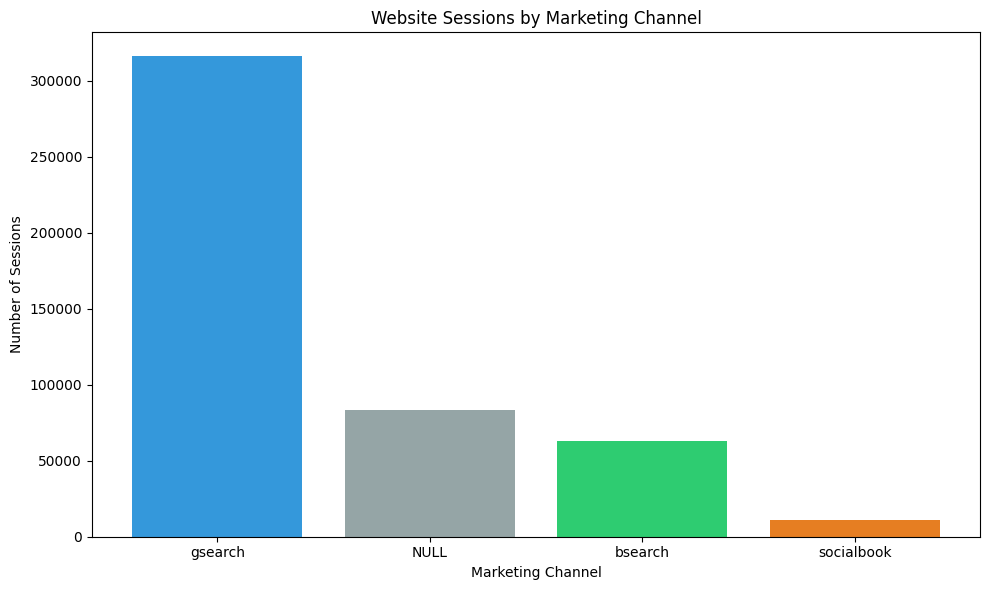

In [0]:
#Marketing channels attracting website sessions
import matplotlib.pyplot as plt

website_sessions = spark.read.table("analystlab.default.website_sessions_2").toPandas()

source_counts = website_sessions['utm_source'].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(
    source_counts.index,
    source_counts.values,
    color=['#3498DB', '#95A5A6', '#2ECC71', '#E67E22']
)

plt.title('Website Sessions by Marketing Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('Number of Sessions')
plt.tight_layout()
plt.show()

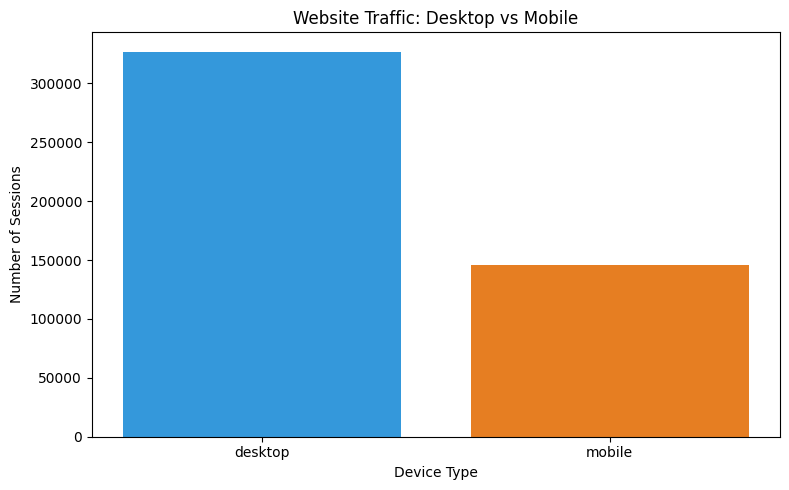

In [0]:
import matplotlib.pyplot as plt

device_counts = website_sessions['device_type'].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    device_counts.index,
    device_counts.values,
    color=['#3498DB', '#E67E22']
)

plt.title('Website Traffic: Desktop vs Mobile')
plt.xlabel('Device Type')
plt.ylabel('Number of Sessions')

plt.tight_layout()
plt.show()